In [116]:
from astropy.io import fits
from pathlib import Path
import numpy as np
import pandas as pd

file = ('hst-data/Calibration/ubai2507m/ubai2507m_blevfile.fits')
with fits.open(file) as hdul:
        #header= hdul[0].header
        #data = hdul[1].data
       # info = hdul.info()
    overscan_region = hdul[2].data[9:790, 8:14]#
    odd = overscan_region[:, 0::2]
    even = overscan_region[:, 1::2]
    mean_odd = np.mean(odd)
    mean_even =  np.mean(even)
file = ('hst-data/Calibration/ubai2507m/ubai2507m_raw.fits')
with fits.open(file) as hdul:
    raw_data = hdul[0].data
    corrected_raw_data = raw_data.copy()
    corrected_raw_data[:, 0::2] = raw_data[:, 0::2] - mean_odd
    corrected_raw_data[:, 1::2] = raw_data[:, 1::2] - mean_even
    #corr_data = raw_data.copy()
    #print(raw_data)
    #raw_data[:, 0::2] = odd_raw
    #raw_data[:, 1::2] = even_raw

#corr_raw_data_odd = odd_raw - mean_odd  
#corr_raw_data_even = even_raw -mean_even 
#corrected_raw_data = np.empty_like(raw_data)
#corrected_raw_data[:, 0::2] = corr_raw_data_odd
#corrected_raw_data[:, 1::2] = corr_raw_data_even
hdul[0].header.get('EXPTIME',0.0)
overscan_region


IndexError: list index out of range

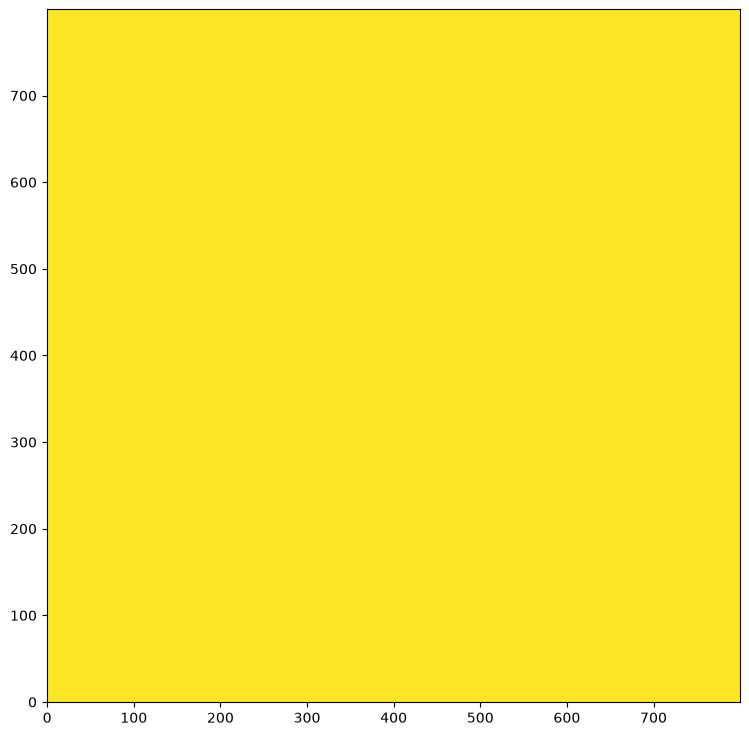

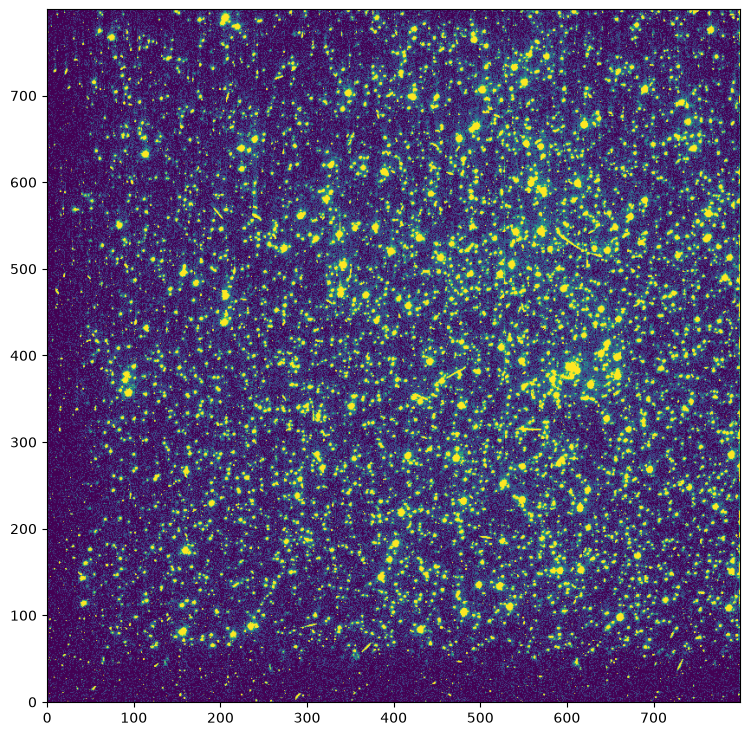

In [105]:
#%matplotlib widget
import matplotlib.pyplot as plt
plt.close('all')

# we'll use the pc chip
pc_data = raw_data[0].copy()
pc_data1 = corrected_raw_data[0].copy()
vmin = pc_data.min()
vmax = pc_data.max()
vmin1 = pc_data1.min()
vmax1 = pc_data1.max()
fig, ax = plt.subplots(figsize=(9, 9))
fig, ax1 = plt.subplots(figsize=(9, 9))
ax.imshow(pc_data, origin='lower', vmin=0, vmax=5)
ax1.imshow(pc_data1, origin='lower', vmin=0, vmax=5)

In [72]:
file = ('hst-data/Calibration/ubai2505m/ubai2505m_biasfile.fits')
with fits.open(file) as hdul:
        #header= hdul[0].header
        #data = hdul[1].data
       # info = hdul.info()
    bias = hdul[0].data
bias_correct = corrected_raw_data-bias
bias_correct

NameError: name 'here' is not defined

In [77]:
file = ('hst-data/Calibration/ubai2505m/ubai2505m_darkfile.fits')
with fits.open(file) as hdul:
        #header= hdul[0].header
        #data = hdul[1].data
       # info = hdul.info()
    dark = hdul[0].data
    hdul[0].header.get('EXPTIME',0.0)
dark_correct = bias_correct-(dark*700)
dark_correct


0.0


In [44]:
file = ('hst-data/Calibration/ubai2505m/ubai2505m_flatfile.fits')
with fits.open(file) as hdul:
        #header= hdul[0].header
        #data = hdul[1].data
       # info = hdul.info()
    flat = hdul[0].data
flat_correct = dark_correct/flat
flat_correct

array([[[-4.53229388e-03, -5.22156665e-03, -3.51394201e-03, ...,
         -8.76737945e-03, -9.89441201e-03, -1.06851682e-01],
        [ 5.83780883e-03, -4.37149359e-03, -3.32309538e-03, ...,
         -1.78729240e-02, -1.07654510e-02, -1.14740685e-01],
        [-2.05377508e-02, -4.99492325e-03, -3.75626236e-03, ...,
         -1.14571154e-02,  2.72728801e-02, -1.32032514e-01],
        ...,
        [-1.19079687e-01, -2.08517443e-02, -1.27340443e-02, ...,
          4.84789997e-01,  3.41444468e+00,  4.37964020e+01],
        [ 8.66949260e-02, -2.34356057e-02, -1.21881459e-02, ...,
          6.00022495e-01,  2.43979335e+00,  1.67816715e+01],
        [ 5.19983377e-03, -8.87601185e+00, -4.15879395e-03, ...,
          5.71430149e-03, -2.81999889e-03,  4.97588469e-03]],

       [[ 6.45493090e-01,  2.07364947e-01,  1.93778396e-01, ...,
          2.53883511e-01,  2.18253925e-01,  2.22469497e+00],
        [ 1.03435183e+00,  2.57166564e-01,  3.16992074e-01, ...,
          2.06448406e-01,  2.24252284e

In [84]:
sum = 0
sum2 = 0
for i in flat_correct:
    
    n = len(flat_correct)
    sum +=i
    
mean = sum/n
for i in flat_correct:
    sum2 += (i - mean)**2
standev = ((1/(n-1))*(sum2))**0.5
condition = ((mean-3*standev)> flat_correct) & (flat_correct>(mean+3*standev))
sky = np.median(condition)
sky_corr = flat_correct - sky
sky_corr

array([[[-4.53229388e-03, -5.22156665e-03, -3.51394201e-03, ...,
         -8.76737945e-03, -9.89441201e-03, -1.06851682e-01],
        [ 5.83780883e-03, -4.37149359e-03, -3.32309538e-03, ...,
         -1.78729240e-02, -1.07654510e-02, -1.14740685e-01],
        [-2.05377508e-02, -4.99492325e-03, -3.75626236e-03, ...,
         -1.14571154e-02,  2.72728801e-02, -1.32032514e-01],
        ...,
        [-1.19079687e-01, -2.08517443e-02, -1.27340443e-02, ...,
          4.84789997e-01,  3.41444468e+00,  4.37964020e+01],
        [ 8.66949260e-02, -2.34356057e-02, -1.21881459e-02, ...,
          6.00022495e-01,  2.43979335e+00,  1.67816715e+01],
        [ 5.19983377e-03, -8.87601185e+00, -4.15879395e-03, ...,
          5.71430149e-03, -2.81999889e-03,  4.97588469e-03]],

       [[ 6.45493090e-01,  2.07364947e-01,  1.93778396e-01, ...,
          2.53883511e-01,  2.18253925e-01,  2.22469497e+00],
        [ 1.03435183e+00,  2.57166564e-01,  3.16992074e-01, ...,
          2.06448406e-01,  2.24252284e

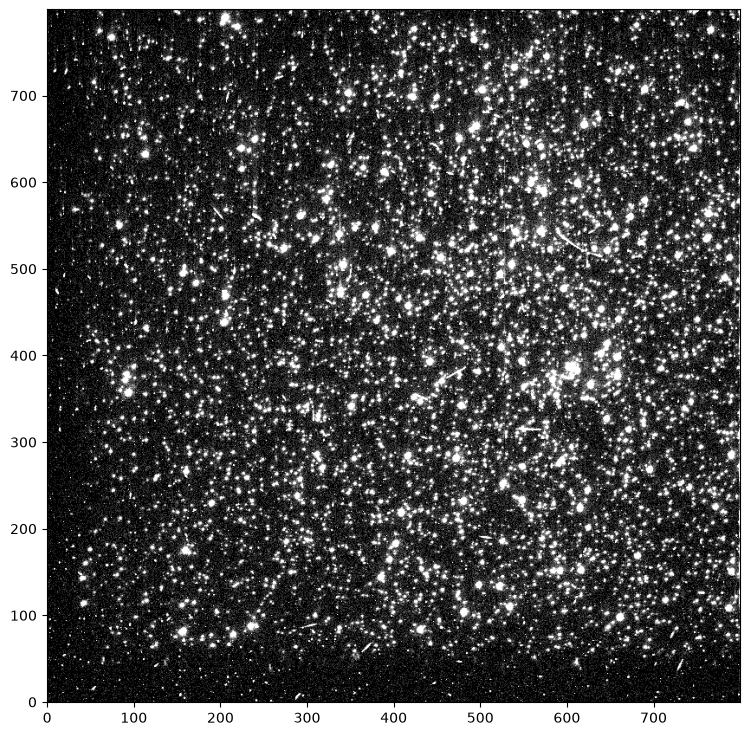

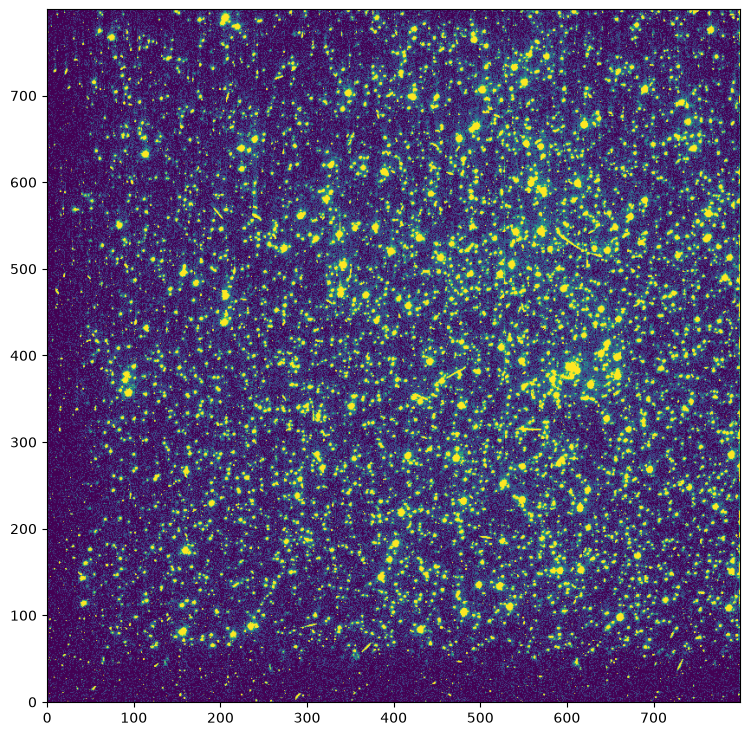

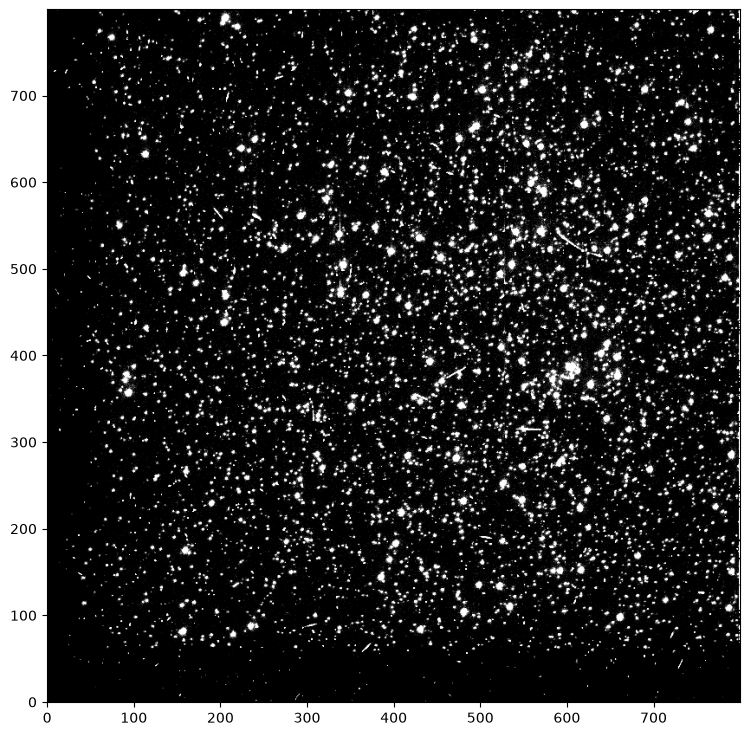

In [96]:
plt.close('all')

# we'll use the pc chip
pc_data = corrected_raw_data[0].copy()
pc_data1 = corrected_raw_data[0].copy()
pc_data2 = sky_subs[0].copy()



fig, ax = plt.subplots(figsize=(9, 9))
fig, ax1 = plt.subplots(figsize=(9, 9))
fig, ax2 = plt.subplots(figsize=(9, 9))

ax.imshow(pc_data, origin='lower',cmap = 'gray', vmin=0, vmax=5)
ax1.imshow(pc_data1, origin='lower', vmin=0, vmax=5)
ax2.imshow(pc_data2, origin='lower',cmap = 'gray', vmin=0, vmax=5)

C:\Users\valer\AppData\Local\Temp\ipykernel_3136\3657302913.py:5: RuntimeWarning: invalid value encountered in log10
  image = -2.5 * np.log10(g)+zer_point


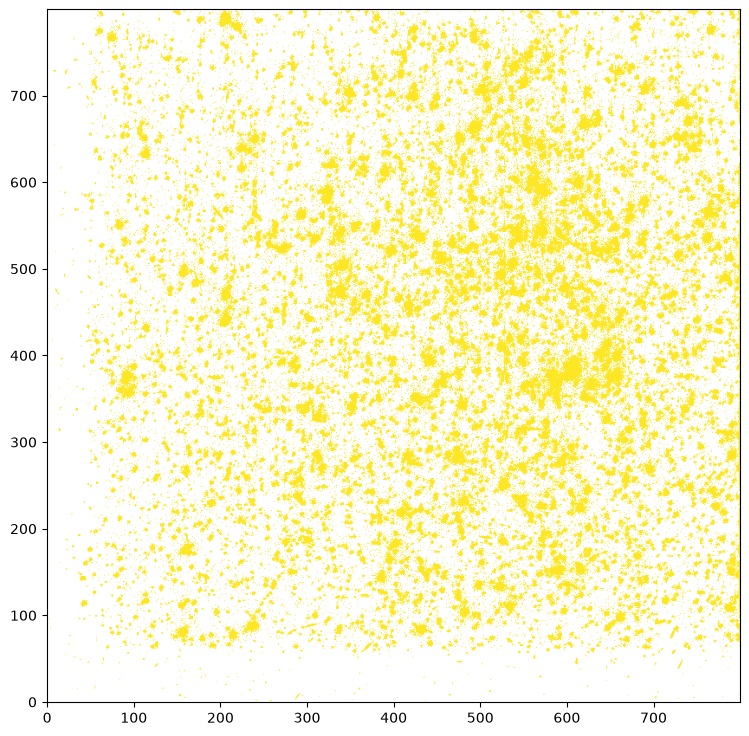

In [87]:
count = sky_subs/700
g =count*1.115396e-16

zer_point = -21.1#*-0.03288031
image = -2.5 * np.log10(g)+zer_point
plt.close('all')

# we'll use the pc chip
pc_data = image[0].copy()


vmin = pc_data.min()
vmax = pc_data.max()


fig, ax = plt.subplots(figsize=(9, 9))



ax.imshow(pc_data, origin='lower', vmin=0, vmax=5)


In [101]:
file = ('hst-data/Calibration/ubai2505m/ubai2505m_maskfile.fits')
with fits.open(file) as hdul:
        #header_mask= hdul[0].header
        data_mask = hdul[0].data
        #info = hdul.info()
condition = (data_mask == 0) #| (data_mask == 256)
masked_raw = np.where(condition, corrected_raw_data, np.nan)
masked_raw


array([[[  0.,   0.,   0., ...,   0.,   0.,  nan],
        [  1.,   0.,   0., ...,   0.,   0.,  nan],
        [  3.,   0.,   0., ...,   0.,   1.,  nan],
        ...,
        [  0.,   0.,   0., ...,   1.,   4.,  nan],
        [  1.,   0.,   0., ...,   1.,   3.,  nan],
        [  1.,   0.,   0., ...,   1.,   0.,  nan]],

       [[ 34.,  21.,  20., ...,  20.,  20.,  nan],
        [ 51.,  26.,  32., ...,  20.,  20.,  nan],
        [185.,  66.,  79., ...,  20.,  20.,  nan],
        ...,
        [ 21.,  20.,  20., ...,  21.,  20.,  nan],
        [ 21.,  20.,  20., ...,  20.,  20.,  nan],
        [ 22.,  20.,  20., ...,  20.,  20.,  nan]],

       [[ 20.,  14.,  14., ...,  14.,  13.,  nan],
        [ 23.,  13.,  14., ...,  13.,  14.,  nan],
        [ 25.,  14.,  14., ...,  15.,  14.,  nan],
        ...,
        [ 14.,  14.,  14., ...,  14.,  14.,  nan],
        [ 14.,  14.,  14., ...,  13.,  13.,  nan],
        [ 13.,  14.,  13., ...,  14.,  14.,  nan]],

       [[  0.,   0.,  -1., ...,   0.,

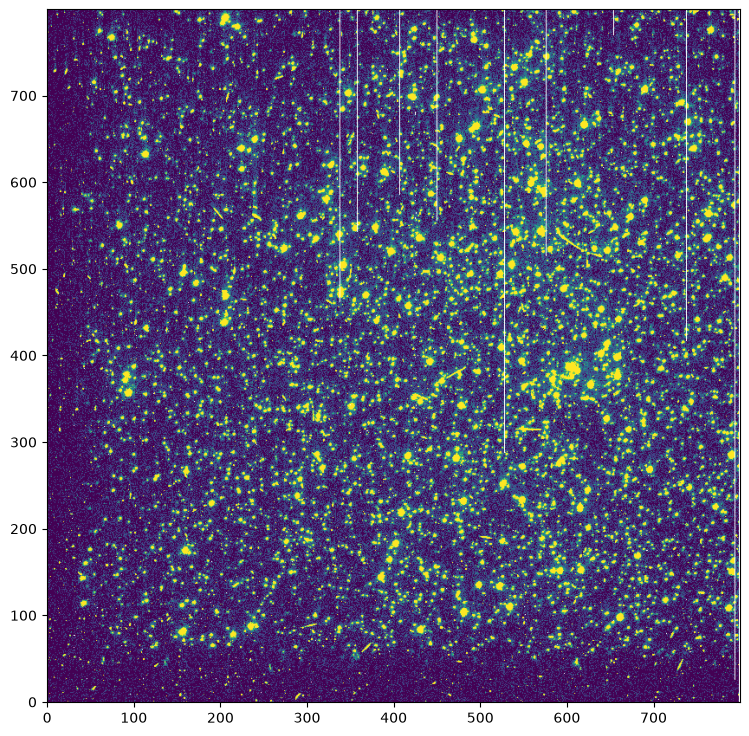

In [102]:
plt.close('all')

# we'll use the pc chip
pc_data = masked_raw[0].copy()




fig, ax = plt.subplots(figsize=(9, 9))



ax.imshow(pc_data, origin='lower', vmin=0, vmax=5)

In [166]:
file = ('hst-data/Calibration/ubai2508m/ubai2508m_maskfile.fits')
with fits.open(file) as hdul:
        #header= hdul[0].header
        #data = hdul[1].data
       # info = hdul.info()
    overscan_region1 = hdul[1].data
#overscan_region
file = ('hst-data/Calibration/ubai2505m/ubai2505m_maskfile.fits')
with fits.open(file) as hdul:
        #header= hdul[0].header
        #data = hdul[1].data
       # info = hdul.info()
    overscan_regionno = hdul[0].data


overscan_regionno

array([[[0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        ...,
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2]],

       [[0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        ...,
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2]],

       [[0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        ...,
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2]],

       [[0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        ...,
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2],
        [0, 0, 0, ..., 0, 0, 2]]], shape=(4, 800, 800), dtype='>i2')